# Fine-tuning Cellpose on the annotation rounds

Trains a new Cellpose model from `cpsam_v2` on the masks corrected in the Cellpose GUI (notebook 02), then segments
the store with it, as one more segmentation (see `macroseg.train`).

- **Images:** every `complete` image under `$MACROSEG_ANNOTATIONS`, read from its store with the channels of the
  segmentation it started from (`membrane_dapi`: NaK_ATPase + DAPI), cut into tiles of `TILE_PX`.
- **Train / test:** images of role `test` go to test whole; the tiles of the others are split, about `TEST_FRACTION`
  to test, with hand-drawn cells on both sides. Tiles of one image look alike, so the test is optimistic
  until whole test images exist.
- **Saved** in `$MACROSEG_MODELS/<NAME>/`: the weights, `tiles.csv` (every tile and its split) and `model.json`
  (start model, channels, images, parameters, losses, versions).

About 10 to 20 s per epoch on the Mac GPU with 16 tiles of 512 px.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from spatialdata import read_zarr

from macroseg import paths
from macroseg.accuracy import score_segmentations
from macroseg.annotation import corrected_masks, image_folder
from macroseg.config import load_config
from macroseg.train import apply_model, load_model_record, tile_mosaic, train, training_set

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = load_config(ROOT / "configs" / "exp201_test_crop.yaml")

NAME = f"{cfg.name}_r01"        # model name: folder in $MACROSEG_MODELS and labels element in the store
START_MODEL = "cpsam_v2"
N_EPOCHS = 20                   # a short run to try the pipeline (config default: cfg.training.n_epochs)
TILE_PX = 512
TEST_FRACTION = 0.2
CHANNELS = None                 # None: the channels of the starting segmentation

/Users/massimoz/Documents/macroseg/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Training set
One row per tile. `hand_drawn`: cells drawn in the GUI (a cell cut by a tile edge counts in both tiles).

In [2]:
data = training_set(paths.path("MACROSEG_ANNOTATIONS"), channels=CHANNELS, tile_px=TILE_PX, test_fraction=TEST_FRACTION)
print("channels:", data.channels)
data.tiles.groupby("split")[["cells", "hand_drawn"]].agg(["count", "sum"])

no parent found for <ome_zarr.reader.Label object at 0x1205c8ad0>: None
no parent found for <ome_zarr.reader.Label object at 0x12057b110>: None
no parent found for <ome_zarr.reader.Label object at 0x12057b4d0>: None
no parent found for <ome_zarr.reader.Label object at 0x1205cd220>: None
no parent found for <ome_zarr.reader.Label object at 0x1205cd6e0>: None


channels: ['NaK_ATPase', 'DAPI']


cells       hand_drawn    
      count   sum      count sum
split                           
test      3   363          3   3
train    13  1464         13  24

In [3]:
data.tiles[data.tiles["split"] == "test"]

,round,image,y0,x0,cells,hand_drawn,split
2,1,exp201_test_crop,0,1024,131,0,test
11,1,exp201_test_crop,1024,1536,122,1,test
14,1,exp201_test_crop,1536,1024,110,2,test


## 2. Train
Learning rate, weight decay and batch size from the config (`training`).

In [4]:
folder = train(
    data,
    paths.path("MACROSEG_MODELS"),
    NAME,
    start_model=START_MODEL,
    n_epochs=N_EPOCHS,
    learning_rate=cfg.training.learning_rate,
    weight_decay=cfg.training.weight_decay,
    batch_size=cfg.training.batch_size,
)
folder

100%|██████████| 3/3 [00:00<00:00, 1121.47it/s]
/Users/massimoz/Documents/macroseg/.venv/lib/python3.13/site-packages/cellpose/train.py:466: UserWarning: In MPS autocast, but the target dtype is not supported. Disabling autocast.
MPS Autocast only supports dtypes of torch.bfloat16, torch.float16 currently.
  with torch.autocast(device_type=device.type, dtype=net.dtype):
/Users/massimoz/Documents/macroseg/.venv/lib/python3.13/site-packages/cellpose/train.py:509: UserWarning: In MPS autocast, but the target dtype is not supported. Disabling autocast.
MPS Autocast only supports dtypes of torch.bfloat16, torch.float16 currently.
  with torch.autocast(device_type=device.type, dtype=net.dtype):


PosixPath('/Users/massimoz/Documents/macroseg/data/models/exp201_test_crop_r01')

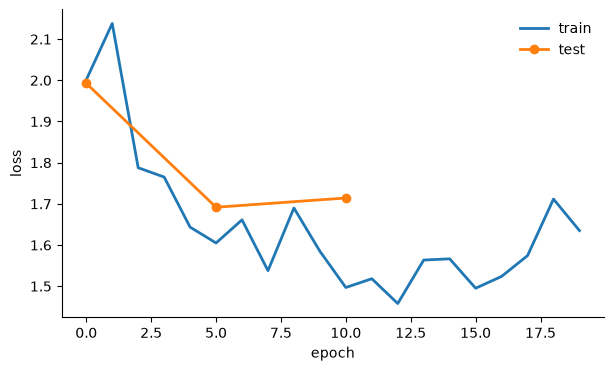

In [5]:
record = load_model_record(folder)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(record["train_losses"], linewidth=2, label="train")
test = {int(epoch): loss for epoch, loss in record["test_losses"].items()}
ax.plot(list(test), list(test.values()), "o-", linewidth=2, markersize=6, label="test")
ax.set_xlabel("epoch")
ax.set_ylabel("loss")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False);

## 3. Segment the store with the new model
Adds the labels element `NAME` and its table `<NAME>_intensities` to the store.

In [6]:
sdata = read_zarr(cfg.zarr)
sdata = apply_model(sdata, cfg.image.element, folder, labels=NAME)
sdata

no parent found for <ome_zarr.reader.Label object at 0x121455010>: None
no parent found for <ome_zarr.reader.Label object at 0x1380fd480>: None
no parent found for <ome_zarr.reader.Label object at 0x1380fd6a0>: None
no parent found for <ome_zarr.reader.Label object at 0x138113250>: None
no parent found for <ome_zarr.reader.Label object at 0x138113450>: None
2026-10-23 11:18:41.634 | INFO     | harpy.image.segmentation._segmentation:_precondition:440 - Provided array is chunked in 'z' and/or 'c' dimension. Will rechunk in 'z' and/or 'c' dimension.
/Users/massimoz/Documents/macroseg/.venv/lib/python3.13/site-packages/cellpose/dynamics.py:541: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internall

SpatialData object, with associated Zarr store: /Users/massimoz/Documents/macroseg/data/runs/exp201_test_crop.zarr
├── Images
│     └── 'macsima_image': DataArray[cyx] (6, 2048, 2048)
├── Labels
│     ├── 'exp201_test_crop_r01': DataArray[yx] (2048, 2048)
│     ├── 'membrane': DataArray[yx] (2048, 2048)
│     ├── 'membrane_dapi': DataArray[yx] (2048, 2048)
│     ├── 'membrane_dapi_f480': DataArray[yx] (2048, 2048)
│     ├── 'nuclei': DataArray[yx] (2048, 2048)
│     └── 'nuclei_expanded': DataArray[yx] (2048, 2048)
└── Tables
      ├── 'exp201_test_crop_r01_intensities': AnnData (1696, 6)
      ├── 'membrane_dapi_f480_intensities': AnnData (1835, 6)
      ├── 'membrane_dapi_intensities': AnnData (1587, 6)
      ├── 'membrane_intensities': AnnData (1441, 6)
      ├── 'nuclei_expanded_intensities': AnnData (1911, 6)
      └── 'nuclei_intensities': AnnData (1911, 6)
with coordinate systems:
    ▸ 'global', with elements:
        macsima_image (Images), exp201_test_crop_r01 (Labels), membr

## 4. Starting segmentation vs new model, on the train and on the test tiles
Each set of tiles is put side by side (`tile_mosaic`) and scored against the corrected masks.
Train tiles were seen in training: only the test tiles say something about new images.

In [7]:
round_number = int(data.tiles.loc[data.tiles["image"] == cfg.name, "round"].iloc[0])
truth, _ = corrected_masks(image_folder(paths.path("MACROSEG_ANNOTATIONS"), round_number, cfg.name))
compare = {name: sdata.labels[name].data.compute() for name in ["membrane_dapi", NAME]}
for split in ["train", "test"]:
    tiles = data.tiles[(data.tiles["split"] == split) & (data.tiles["image"] == cfg.name)]
    table = score_segmentations(
        tile_mosaic(truth, tiles, TILE_PX), {k: tile_mosaic(v, tiles, TILE_PX) for k, v in compare.items()}
    )
    print(f"{split} tiles ({len(tiles)})")
    display(table.T.round(3))

train tiles (13)


segmentation,membrane_dapi,exp201_test_crop_r01
true_cells,1464.000,1464.000
segmented_cells,1497.000,1596.000
AP@0.5,0.957,0.813
precision@0.5,0.967,0.860
recall@0.5,0.989,0.937
AP@0.75,0.948,0.709
precision@0.75,0.963,0.796
recall@0.75,0.984,0.867
AP@0.9,0.947,0.401
precision@0.9,0.962,0.549


test tiles (3)


segmentation,membrane_dapi,exp201_test_crop_r01
true_cells,363.000,363.000
segmented_cells,371.000,399.000
AP@0.5,0.963,0.850
precision@0.5,0.970,0.877
recall@0.5,0.992,0.964
AP@0.75,0.963,0.756
precision@0.75,0.970,0.822
recall@0.75,0.992,0.904
AP@0.9,0.963,0.457
precision@0.9,0.970,0.599
